# Step 5b — Temporal transferability test (SVM vs GAEZ, MIRCA-OS 2000/2005/2010/2015)

**Question** (raised by the supervisor, "to be checked"): does the SVM's learned climate->presence
relationship (fit once, on MIRCA2000 + ERA5 1981-2015 climatology) still hold up when checked against
*later, independently observed* crop-presence snapshots — or was it only ever a good fit to the
specific year-2000 socio-economic situation?

**Design (Version A, agreed)**: keep the climate input fixed (the same static 1981-2015 ERA5
climatology used to train/predict throughout this pipeline -- `suit_proba` from
`4.a)_SVM_predict_ERA5_1deg_MIRCA2000_threshold5pct.ipynb`) and swap only the ground-truth year, using
[MIRCA-OS](../../0_Input_data/masks_crops/MIRCA_OS) (a genuinely independent, newer product with
real annual harvested-area grids for 2000, 2005, 2010 and 2015 -- not the same MIRCA2000 calendar
file used to build the training label). This isolates *non-climatic temporal drift* in realized land
use (economics, variety/technology change, crop-choice shifts) from any climate-driven effect, since
climate is held constant across all 4 evaluations -- see
[svm-eastern-europe-gap-vs-gaez.md](memory) for why this distinction matters and why this is a
historical proxy, not a true test of extrapolation to an out-of-distribution climate like AMOC-hosing.

**Reading the result**: if AUC stays roughly flat across 2000->2005->2010->2015, the climate-presence
relationship the SVM learned looks durable over 15 years of real land-use change -- reassuring for
applying it unchanged to other periods. If AUC declines with the time gap, that is evidence the SVM
partly fit something tied to the 2000 snapshot specifically, a relevant caveat for applying it, as-is,
to a future (AMOC) climate state. **GAEZ v5 is included as a control**: GAEZ was never fit to MIRCA at
all, so if its AUC against MIRCA-OS *also* drifts with year, that points to MIRCA-OS/land-use drift in
general rather than something specific to the SVM's training.


In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, xarray as xr, rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_auc_score

BASE        = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
ERA5_DIR    = BASE / "1_SVM" / "1_preprocessing_BIOvariables" / "1.1)_preprocessing_biovariables_ERA5" / "outputs_ERA5_MIRCA2000_threshold5pct"
CLIMATE_DIR = BASE / "1_SVM" / "4_SVM_predict" / "4.a)_SVM_predict_ERA5_1deg_MIRCA2000_threshold5pct" / "svm_predict_outputs_ERA5_1deg"
GAEZ_DIR    = cu.data_dir(CFG, "gaez_v5_hist")  # data path: see 00_config_and_inventory.ipynb
MIRCA_OS_DIR = BASE / "0_Input_data" / "masks_crops" / "MIRCA_OS" / "Annual Harvested Area Grids" / "Annual Harvested Area Grids"
CELL_AREA_FILE = BASE / "0_Input_data" / "masks_crops" / "MIRCA_2000" / "cell_area_grid" / "cell_area_ha.npy"
OUT_DIR = BASE / "1_SVM" / "5_Suitability_climate_soil_combined_validation" / "5.e)_SVM_temporal_transferability" / "temporal_transferability_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CROPS = ['Maize_rf', 'Wheat-spring_rf', 'Wheat-winter_rf']
# MIRCA-OS does not split wheat by season (same limitation already accepted for the GAEZ soil-only
# panels in 5.a) -- both wheat labels share the same "Wheat" MIRCA-OS file, flagged below.
MIRCA_OS_CROP = {'Maize_rf': 'Maize', 'Wheat-spring_rf': 'Wheat', 'Wheat-winter_rf': 'Wheat'}
GAEZ_CODE = {'Maize_rf': 'MZE', 'Wheat-spring_rf': 'WHE', 'Wheat-winter_rf': 'WHE'}
YEARS = [2000, 2005, 2010, 2015]
CROP_THR = 0.05  # same 5% threshold used everywhere else in this pipeline for a 'cultivated' pixel/cell

print("Input files:")
for crop in CROPS:
    p = CLIMATE_DIR / f'suitability_ERA5_{crop}.nc'
    print(f'  {"OK" if p.exists() else "MISSING"}: {p.name}')
for crop in set(MIRCA_OS_CROP.values()):
    for year in YEARS:
        p = MIRCA_OS_DIR / str(year) / "5-arcminute" / f"MIRCA-OS_{crop}_{year}_rf.tif"
        print(f'  {"OK" if p.exists() else "MISSING"}: {p}')

Input files:
  OK: suitability_ERA5_Maize_rf.nc
  OK: suitability_ERA5_Wheat-spring_rf.nc
  OK: suitability_ERA5_Wheat-winter_rf.nc
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\0_Input_data\masks_crops\MIRCA_OS\Annual Harvested Area Grids\Annual Harvested Area Grids\2000\5-arcminute\MIRCA-OS_Maize_2000_rf.tif
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\0_Input_data\masks_crops\MIRCA_OS\Annual Harvested Area Grids\Annual Harvested Area Grids\2005\5-arcminute\MIRCA-OS_Maize_2005_rf.tif
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\0_Input_data\masks_crops\MIRCA_OS\Annual Harvested Area Grids\Annual Harvested Area Grids\2010\5-arcminute\MIRCA-OS_Maize_2010_rf.tif
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\0_Input_data\masks_crops\MIRCA_OS\Annual Harvested Area Grids\Annual Harvested Area Grids\2015\5-arcmi

## 1. Grid, climate proba (SVM), GAEZ v5 (control)

In [2]:
ds_grid = xr.open_dataset(ERA5_DIR / 'BIOvariables_ERA5_1981_2015_1deg_Maize_rf.nc')
target_lats_asc = ds_grid.lat.values
target_lons     = ds_grid.lon.values
ds_grid.close()

land_mask = np.zeros((len(target_lats_asc), len(target_lons)), dtype=bool)
for crop in CROPS:
    ds_c = xr.open_dataset(ERA5_DIR / f'BIOvariables_ERA5_1981_2015_1deg_{crop}.nc')
    land_mask |= np.isfinite(ds_c['BIO01'].values)
    ds_c.close()

nlat, nlon = len(target_lats_asc), len(target_lons)
LAT_MIN_EDGE, LAT_MAX_EDGE = target_lats_asc[0] - 0.5, target_lats_asc[-1] + 0.5
LON_MIN_EDGE, LON_MAX_EDGE = target_lons[0] - 0.5, target_lons[-1] + 0.5
print(f"Grid: {nlat} lat x {nlon} lon, {land_mask.sum()} land cells")


def load_climate_proba(crop):
    ds = xr.open_dataset(CLIMATE_DIR / f'suitability_ERA5_{crop}.nc')
    arr = ds['suit_proba'].values
    ds.close()
    return arr


suit_climate = {crop: load_climate_proba(crop) for crop in CROPS}

# GAEZ v5 SIX (high input, rainfed), 1deg -- same conversion as 5.a)_Apply_ERA5_validation.ipynb
GAEZ_SI_MIDPOINTS = {0: np.nan, 1: 0.925, 2: 0.775, 3: 0.625, 4: 0.475, 5: 0.325,
                      6: 0.175, 7: 0.05, 8: 0.0, 9: np.nan}


def load_gaez_v5_six_1deg(path):
    with rasterio.open(path) as src:
        res = src.transform.a
        ulx, uly = src.transform.c, src.transform.f
        px_per_deg = round(1.0 / res)
        col_start = round((LON_MIN_EDGE - ulx) / res)
        row_start = round((uly - LAT_MAX_EDGE) / res)
        col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / res)
        row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / res)
        raw = src.read(1, window=Window(col_start, row_start, col_count, row_count))
    score = np.vectorize(GAEZ_SI_MIDPOINTS.get)(raw).astype(float)
    assert score.shape == (nlat * px_per_deg, nlon * px_per_deg)
    blocks = score.reshape(nlat, px_per_deg, nlon, px_per_deg)
    with np.errstate(invalid='ignore'):
        out = np.nanmean(blocks, axis=(1, 3))[::-1, :]
    return np.where(land_mask, out, np.nan)


suit_gaez = {crop: load_gaez_v5_six_1deg(GAEZ_DIR / f'GAEZ-V5.RES05-SIX.HP8100.AGERA5.HIST.{GAEZ_CODE[crop]}.HRLM.tif')
             for crop in CROPS}
print('GAEZ v5 loaded (high input, rainfed) for', list(suit_gaez.keys()))

Grid: 37 lat x 70 lon, 1332 land cells


GAEZ v5 loaded (high input, rainfed) for ['Maize_rf', 'Wheat-spring_rf', 'Wheat-winter_rf']


## 2. MIRCA-OS presence at 1deg, for 2000/2005/2010/2015

Same two-level 5% threshold convention as the MIRCA2000 training label itself
(`0_preprocessing_masks/0.1)_preprocessing_input_data.ipynb`, and as the native-resolution panel added to
`5.a)_Apply_ERA5_validation.ipynb`): a 5 arc-min pixel counts as 'cultivated' if its harvested-area
fraction of its own pixel area is > 5%; a 1deg cell counts as 'cultivated' (label=1) if more than 5%
of its *land* 5 arc-min pixels are themselves cultivated. Reuses the same 5 arc-min global grid
(`cell_area_ha.npy`, Natural Earth land mask) as the MIRCA2000 calendar-based build.

In [3]:
import regionmask

LAT0, LAT1 = int(target_lats_asc.min()), int(target_lats_asc.max())
LON0, LON1 = int(target_lons.min()), int(target_lons.max())

NROW, NCOL = 2160, 4320
ROWS_, COLS_ = np.arange(NROW), np.arange(NCOL)
lat5 = 90 - (ROWS_ + 0.5) / 12
lon5 = -180 + (COLS_ + 0.5) / 12
lat5_i = np.floor(lat5 + 0.5).astype(int)
lon5_i = np.floor(lon5 + 0.5).astype(int)
R5 = np.where((lat5_i >= LAT0) & (lat5_i <= LAT1))[0]
C5 = np.where((lon5_i >= LON0) & (lon5_i <= LON1))[0]
AREA5 = np.load(CELL_AREA_FILE)[np.ix_(R5, C5)]  # ha per 5 arc-min pixel

land_rg = regionmask.defined_regions.natural_earth_v5_0_0.land_10
land5 = np.isfinite(land_rg.mask(lon5[C5], lat5[R5]).values)
print('5 arc-min window:', len(R5), 'x', len(C5), '-- land pixels:', int(land5.sum()))


def mirca_os_presence_1deg(crop_mirca, year):
    path = MIRCA_OS_DIR / str(year) / "5-arcminute" / f"MIRCA-OS_{crop_mirca}_{year}_rf.tif"
    with rasterio.open(path) as src:
        area = src.read(1, window=Window(int(C5[0]), int(R5[0]), len(C5), len(R5))).astype(float)
    cropped5 = land5 & ((area / AREA5) > CROP_THR)  # pixel-level 5%
    n_land = land5.reshape(nlat, 12, nlon, 12).sum(axis=(1, 3))
    n_crop = cropped5.reshape(nlat, 12, nlon, 12).sum(axis=(1, 3))
    with np.errstate(invalid='ignore'):
        pres = (n_land > 0) & (n_crop / np.maximum(n_land, 1) > CROP_THR)  # cell-level 5%
    pres = pres.astype(float)[::-1, :]  # flip to ascending-lat, matching suit_climate's orientation
    return np.where(land_mask, pres, np.nan)


mirca_os_1deg = {crop: {year: mirca_os_presence_1deg(MIRCA_OS_CROP[crop], year) for year in YEARS}
                  for crop in CROPS}
for crop in CROPS:
    print(crop, {year: int(np.nansum(mirca_os_1deg[crop][year])) for year in YEARS})

5 arc-min window: 444 x 840 -- land pixels: 175844


Maize_rf {2000: 109, 2005: 123, 2010: 199, 2015: 244}
Wheat-spring_rf {2000: 685, 2005: 744, 2010: 742, 2015: 742}
Wheat-winter_rf {2000: 685, 2005: 744, 2010: 742, 2015: 742}


## 3. AUC vs. time gap -- SVM (climate-only) vs GAEZ v5, both against each MIRCA-OS year

Climate input is identical across all 4 points for a given crop (same static 1981-2015 ERA5
climatology, same `suit_climate`/`suit_gaez` arrays) -- only the ground-truth year changes. This
isolates non-climatic temporal drift in realized land use; it is **not** a test of extrapolation to a
genuinely different (e.g. AMOC-hosing) climate regime -- see the markdown at the top.

In [4]:
rows = []
for crop in CROPS:
    for year in YEARS:
        truth = mirca_os_1deg[crop][year]
        for label, arr in [('SVM climate-only', suit_climate[crop]), ('GAEZ v5 (control)', suit_gaez[crop])]:
            both = np.isfinite(truth) & np.isfinite(arr) & land_mask
            if both.sum() < 10 or len(np.unique(truth[both])) < 2:
                auc = np.nan
            else:
                auc = roc_auc_score(truth[both], arr[both])
            rows.append(dict(crop=crop, year=year, gap_years=year - 2000, model=label,
                              n=int(both.sum()), auc=auc))

auc_df = pd.DataFrame(rows).round(3)
print(auc_df.to_string(index=False))
auc_df.to_csv(OUT_DIR / 'temporal_transferability_auc.csv', index=False)

           crop  year  gap_years             model    n   auc
       Maize_rf  2000          0  SVM climate-only 1332 0.919
       Maize_rf  2000          0 GAEZ v5 (control) 1332 0.851
       Maize_rf  2005          5  SVM climate-only 1332 0.916
       Maize_rf  2005          5 GAEZ v5 (control) 1332 0.845
       Maize_rf  2010         10  SVM climate-only 1332 0.938
       Maize_rf  2010         10 GAEZ v5 (control) 1332 0.911
       Maize_rf  2015         15  SVM climate-only 1332 0.908
       Maize_rf  2015         15 GAEZ v5 (control) 1332 0.934
Wheat-spring_rf  2000          0  SVM climate-only 1332 0.520
Wheat-spring_rf  2000          0 GAEZ v5 (control) 1332 0.798
Wheat-spring_rf  2005          5  SVM climate-only 1332 0.595
Wheat-spring_rf  2005          5 GAEZ v5 (control) 1332 0.750
Wheat-spring_rf  2010         10  SVM climate-only 1332 0.565
Wheat-spring_rf  2010         10 GAEZ v5 (control) 1332 0.776
Wheat-spring_rf  2015         15  SVM climate-only 1332 0.541
Wheat-sp

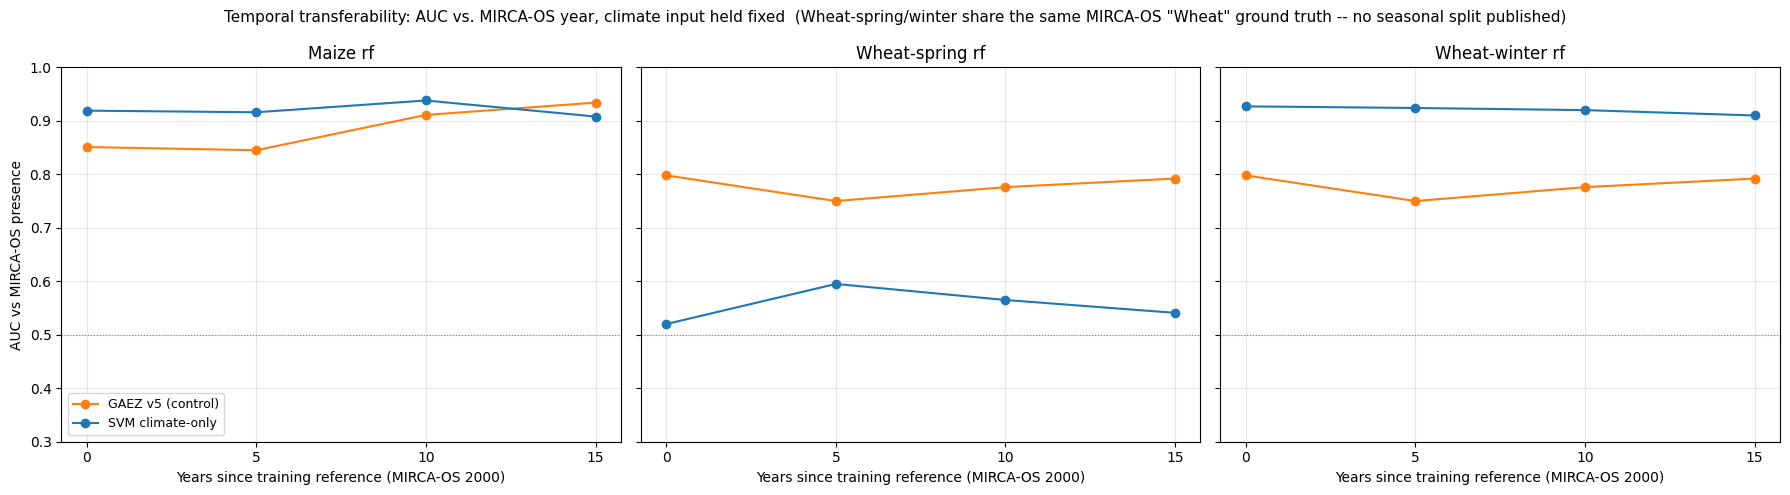

In [5]:
fig, axes = plt.subplots(1, len(CROPS), figsize=(6 * len(CROPS), 5), sharey=True)
colors = {'SVM climate-only': '#1f77b4', 'GAEZ v5 (control)': '#ff7f0e'}
for ax, crop in zip(axes, CROPS):
    sub = auc_df[auc_df.crop == crop]
    for model, g in sub.groupby('model'):
        g = g.sort_values('gap_years')
        ax.plot(g['gap_years'], g['auc'], marker='o', label=model, color=colors[model])
    ax.set_title(crop.replace('_', ' '))
    ax.set_xlabel('Years since training reference (MIRCA-OS 2000)')
    ax.set_xticks(YEARS[0] - 2000 + np.array([0, 5, 10, 15]))
    ax.axhline(0.5, color='grey', linewidth=0.8, linestyle=':')
    ax.set_ylim(0.3, 1.0)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('AUC vs MIRCA-OS presence')
axes[0].legend(loc='lower left', fontsize=9)
note = '  (Wheat-spring/winter share the same MIRCA-OS "Wheat" ground truth -- no seasonal split published)'
plt.suptitle('Temporal transferability: AUC vs. MIRCA-OS year, climate input held fixed' + note, fontsize=11)
plt.tight_layout()
plt.savefig(OUT_DIR / 'temporal_transferability_auc_vs_gap.png', dpi=130, bbox_inches='tight')
plt.show()

## Conclusion

Read the AUC-vs-gap plot per crop: a flat (or non-monotonic/noisy-flat) **SVM climate-only** line
across 2000->2015 supports temporal stability of the learned climate-presence relationship over 15
years of real observed land-use change. A declining trend is evidence of drift tied to something
beyond climate (the 2000 snapshot's own economic/technological/variety context) -- relevant, not
decisive, caution for applying this SVM unchanged to a future (AMOC-hosing) climate projection where
no such drift could ever be measured directly.

The **GAEZ v5 control** line shows whether MIRCA-OS itself drifts away from a purely climate-based,
never-trained-on-MIRCA reference over the same period -- if GAEZ's AUC also declines with year, that
points to a MIRCA-OS/land-use signal, not something specific to SVM overfitting; if GAEZ stays flat
while SVM declines, that isolates the drift as SVM-specific.

This is still, as discussed, a *historical* temporal-transferability proxy (Version A: climate held
fixed, only the realized-land-use ground truth changes) -- not a true test of extrapolation to an
out-of-distribution climate state. See [[svm-eastern-europe-gap-vs-gaez]] for the fuller discussion
of why that distinction matters, and the supervisor's framing this analysis is responding to.
